# Tunisian–French code-switching detection in Latin-script Tunisian (Arabizi)

**Task.** Label **every word** of a Tunisian social-media sentence as

* **TUN** – Tunisian Arabic written in Latin letters and digits (*Arabizi*: `3andi`, `n7ebek`, `barcha`, `ya5i`)
* **FOR** – a code-switched foreign word (mostly **French**, some English: `mais`, `vraiment`, `stress`, `weekend`)

```
ena  berjoulia  kont  8ebel  3al  5arja  mais  ba3d  ma5rejt  kra8et8a  w    3eftha
TUN  TUN        TUN   TUN    TUN  TUN    FOR   TUN   TUN      TUN       TUN  TUN
```

**Why it is a real NLP problem.** Both languages share the *same alphabet*, so there is no "Arabic letters vs Latin letters"
shortcut. A model must use spelling patterns (digits used as letters, French morphology, accents) and **context**: `la` is Tunisian
*"no"* in `la la ma n7ebch` but the French article in `la fac`.

**Data.** TArC – *Tunisian Arabish Corpus* (Gugliotta & Dinarelli, LREC 2022), <https://github.com/eligugliotta/tarc>,
CC BY-NC-SA 4.0. Every token's `arabizi` / `foreign` class was manually checked by the authors.

**Code organisation.** Reusable code lives in `src/tuncs/` (data, metrics, models); this notebook tells the story and calls it.

| § | Content |
|---|---|
| 1–2 | Corpus and cleaning policy |
| 3 | Exploratory analysis |
| 4 | Preprocessing and split |
| 5 | Evaluation metrics |
| 6–10 | Models: baselines → char n-gram LogReg → CRF → BiLSTM-CRF → XLM-R |
| 11–13 | Results, error analysis, cross-genre robustness |
| 14–15 | Live demo, conclusion |

In [1]:
import sys, re, warnings
from collections import Counter
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

warnings.filterwarnings("ignore", message="IProgress not found")  # cosmetic tqdm notice in Jupyter

from tuncs.config import COLORS, FIGURES, LABELS, RAW_TSV, SEED, TABLES
from tuncs.data import (read_raw, load_corpus, deduplicate, split, save_jsonl, word_label_counts,
                        is_code_switched, make_sentence, tokenize_text, PROCESSED)
from tuncs.metrics import evaluate
from tuncs.experiment import train_or_load, score, results_table, save_results, plot_results, tag_string
from tuncs.models import MajorityTagger, LexiconTagger, CharNgramTagger, CRFTagger

# False = reuse the models already saved in models/ (fast, for presenting); True = retrain everything (~10 min on GPU).
RETRAIN = False

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
pd.set_option("display.max_colwidth", 120)
print("device:", "cuda" if torch.cuda.is_available() else "cpu", "| RETRAIN =", RETRAIN)

device: cuda | RETRAIN = False


## 1. The corpus

`data/raw/tarc.tsv` has one token per line and an `<eos>` line between sentences. We use `TYPE` (genre: social, forum, blog,
rap), `arabish` (the word as written) and `class` (`arabizi` / `foreign` / `emotag`). Other columns are annotation layers we do not need.

### 1.1 The raw file, loaded as it is with pandas

`tarc.tsv` is a tab-separated file. Two options keep it exactly as written:
* `quoting=csv.QUOTE_NONE`, because tokens such as `"` or `'` are words, not quote marks;
* `keep_default_na=False`, so tokens like `nan` or `NA` stay strings instead of becoming missing values.

In [2]:
import csv

df = pd.read_csv(RAW_TSV, sep="	", quoting=csv.QUOTE_NONE, keep_default_na=False, dtype=str)
print("shape:", df.shape)
df.head(10)

shape: (48126, 11)


,TYPE,data,arabish,class,CODA,token,pos,lemma,governorate,age,gender
0,forum,20150902,3rabfieurope2011:,arabizi,عرب في اوروبا 2011 :,عرب+في+اوروبا+2011+:,NOUN+PREP+NOUN_PROP+NOUN_NUM+PUNC,عربي,Bizerte,25-35,M
1,forum,20150902,kifech,arabizi,كيفاش,كيفاش,INTERROG_ADV,كيفاش,Bizerte,25-35,M
2,forum,20150902,tchoufou,arabizi,تشوفوا,تشوفوا,IV2P-IV-IVSUFF_SUBJ:P,شاف,Bizerte,25-35,M
3,forum,20150902,l3icha,arabizi,العيشة,ال+عيشة,DET+NOUN-NSUFF_FEM_SG,عيشة,Bizerte,25-35,M
4,forum,20150902,fi8al,arabizi,فال,في+ال,PREP+DET,في,Bizerte,25-35,M
5,forum,20150902,5orba,arabizi,غربة,غربة,NOUN-NSUFF_FEM_SG,غربة,Bizerte,25-35,M
6,forum,20150902,?,arabizi,؟,؟,PUNC,PUNC,Bizerte,25-35,M
7,forum,<eos>,<eos>,<eos>,<eos>,<eos>,<eos>,<eos>,<eos>,<eos>,<eos>
8,forum,20150902,Ena,arabizi,انا,انا,PRON_1S,هو,Bizerte,25-35,M
9,forum,20150902,berjoulia,arabizi,بالرجولية,ب+ال+رجولية,PREP+DET+NOUN-NSUFF_FEM_SG,رجوليّة,Bizerte,25-35,M


### 1.2 Simple descriptive statistics

Each row is one token; rows whose `arabish` value is `<eos>` only mark the end of a sentence.

In [3]:
is_eos = df["arabish"] == "<eos>"
tok = df[~is_eos].copy()
tok["length"] = tok["arabish"].str.len()
tok["sentence"] = is_eos.cumsum()[~is_eos]  # sentence number of each token

print(f"rows: {len(df):,} | token rows: {len(tok):,} | sentences: {is_eos.sum():,}")
print(f"distinct word forms: {tok['arabish'].str.lower().nunique():,}")

# count / unique / most frequent value for every column
display(tok[["TYPE", "arabish", "class", "governorate", "age", "gender"]].describe())

# label distribution
cls = tok["class"].value_counts().to_frame("tokens")
cls["%"] = (100 * cls.tokens / cls.tokens.sum()).round(1)
display(cls)

# labels per genre
display(pd.crosstab(tok["TYPE"], tok["class"], margins=True, margins_name="total"))

# word length (characters) and sentence length (tokens)
display(tok.groupby("class")["length"].describe().round(2))
display(tok.groupby("sentence").size().describe().round(2).to_frame("tokens per sentence").T)

rows: 48,126 | token rows: 43,328 | sentences: 4,798
distinct word forms: 15,454


,TYPE,arabish,class,governorate,age,gender
count,43328,43328,43328,43328,43328,43328
unique,4,16303,4,59,5,3
top,social,",",arabizi,/,/,/
freq,16057,1288,31498,22191,20277,18548


,tokens,%
class,,
arabizi,31498,72.7
foreign,11212,25.9
emotag,617,1.4
nan,1,0.0


class,arabizi,emotag,foreign,nan,total
TYPE,,,,,
blog,5958,7,706,0,6671
forum,6026,10,5873,0,11909
rap,7680,1,1010,0,8691
social,11834,599,3623,1,16057
total,31498,617,11212,1,43328


,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
arabizi,31498.0,4.83,3.03,1.0,3.0,5.0,6.0,143.0
emotag,617.0,5.61,11.62,1.0,2.0,2.0,4.0,59.0
foreign,11212.0,4.75,2.98,1.0,3.0,4.0,6.0,52.0
nan,1.0,7.00,NaN,7.0,7.0,7.0,7.0,7.0


,count,mean,std,min,25%,50%,75%,max
tokens per sentence,4798.0,9.03,9.64,1.0,2.0,5.0,12.0,59.0


In [4]:
header, raw_rows, raw_sents = read_raw(RAW_TSV)
display(pd.DataFrame(raw_rows[:12], columns=header)[["TYPE", "arabish", "class", "CODA", "governorate"]])
print(f"{len(raw_sents):,} sentences, {sum(len(s['tokens']) for s in raw_sents):,} tokens")
print("raw classes:", Counter(c for s in raw_sents for c in s["classes"]))

,TYPE,arabish,class,CODA,governorate
0,forum,3rabfieurope2011:,arabizi,عرب في اوروبا 2011 :,Bizerte
1,forum,kifech,arabizi,كيفاش,Bizerte
2,forum,tchoufou,arabizi,تشوفوا,Bizerte
3,forum,l3icha,arabizi,العيشة,Bizerte
4,forum,fi8al,arabizi,فال,Bizerte
5,forum,5orba,arabizi,غربة,Bizerte
6,forum,?,arabizi,؟,Bizerte
7,forum,<eos>,<eos>,<eos>,<eos>
8,forum,Ena,arabizi,انا,Bizerte
9,forum,berjoulia,arabizi,بالرجولية,Bizerte


4,798 sentences, 43,328 tokens
raw classes: Counter({'arabizi': 31498, 'foreign': 11212, 'emotag': 617, 'nan': 1})


## 2. Cleaning and label policy

Only lexical tokens are scored. All rules are deterministic (see `tuncs.data.clean_sentence`):

| Raw token | Decision | Why |
|---|---|---|
| `arabizi` | **TUN** | Tunisian (or MSA) in Latin script |
| `foreign` | **FOR** | code-switched French / English |
| `emotag` (😂, `<3`, `:p`) | removed | not a language |
| no letter (`?`, `2011`, `***`) | removed | punctuation / numbers |
| `m5abbiNNNN` | removed | anonymised user names inserted by the corpus authors |
| `\'` | → `'` | export artefact (`j\'ai` → `j'ai`) |
| one `nan` token (`yarhmek`) | → TUN | clearly Tunisian (*"God bless you"*) |

In [5]:
sents, drop_log = load_corpus()
display(pd.Series(drop_log, name="removed / changed tokens").to_frame())
print(f"kept {len(sents):,} sentences, {sum(len(s['tokens']) for s in sents):,} word tokens")
ex = next(s for s in sents if is_code_switched(s["labels"]) and len(s["tokens"]) < 14)
display(pd.DataFrame({"token": ex["tokens"], "label": ex["labels"]}).T)

,removed / changed tokens
no letter (punct/number),4148
user placeholder,2986
emotag,617
nan relabelled TUN,1


kept 3,960 sentences, 35,577 word tokens


,0,1,2,3,4,5,6,7,8,9,10,11
token,Ena,berjoulia,kont,8ebel,3al,5arja,mais,ba3d,ma5rejt,kra8et8a,w,3eftha
label,TUN,TUN,TUN,TUN,TUN,TUN,FOR,TUN,TUN,TUN,TUN,TUN


## 3. Exploratory data analysis

,sentences,words,FOR,cs_sentences,mean_len,FOR_%,cs_sent_%
genre,,,,,,,
blog,366.0,5533.0,701.0,137.0,15.1,12.7,37.4
forum,753.0,10708.0,5695.0,467.0,14.2,53.2,62.0
rap,515.0,8318.0,1009.0,276.0,16.2,12.1,53.6
social,2326.0,11018.0,3507.0,455.0,4.7,31.8,19.6
ALL,3960.0,35577.0,10912.0,1335.0,9.0,30.7,33.7


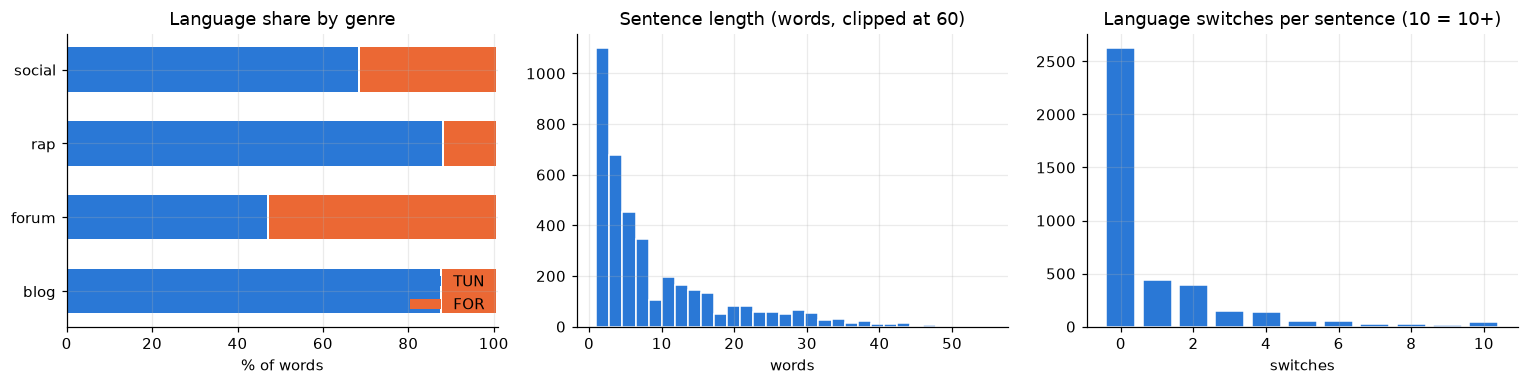

In [6]:
n_switches = lambda labels: sum(a != b for a, b in zip(labels, labels[1:]))
eda = pd.DataFrame([{"genre": s["genre"], "words": len(s["tokens"]), "FOR": s["labels"].count("FOR"),
                     "code_switched": is_code_switched(s["labels"]), "switches": n_switches(s["labels"])} for s in sents])
by_genre = eda.groupby("genre").agg(sentences=("words", "size"), words=("words", "sum"), FOR=("FOR", "sum"),
                                     cs_sentences=("code_switched", "sum"), mean_len=("words", "mean"))
by_genre.loc["ALL"] = [len(eda), eda.words.sum(), eda.FOR.sum(), eda.code_switched.sum(), eda.words.mean()]
by_genre["FOR_%"] = 100 * by_genre.FOR / by_genre.words
by_genre["cs_sent_%"] = 100 * by_genre.cs_sentences / by_genre.sentences
display(by_genre.round(1))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
g = by_genre.drop("ALL"); tun_pct = 100 - g["FOR_%"]
axes[0].barh(g.index, tun_pct, color=COLORS["TUN"], label="TUN", height=0.6)
axes[0].barh(g.index, g["FOR_%"], left=tun_pct + 0.6, color=COLORS["FOR"], label="FOR", height=0.6)
axes[0].set_xlim(0, 101); axes[0].set_xlabel("% of words"); axes[0].set_title("Language share by genre")
axes[0].legend(loc="lower right", frameon=False)
axes[1].hist(eda.words.clip(upper=60), bins=30, color=COLORS["TUN"], edgecolor="white")
axes[1].set_title("Sentence length (words, clipped at 60)"); axes[1].set_xlabel("words")
sw = eda.switches.clip(upper=10).value_counts().sort_index()
axes[2].bar(sw.index, sw.values, color=COLORS["TUN"], edgecolor="white")
axes[2].set_title("Language switches per sentence (10 = 10+)"); axes[2].set_xlabel("switches")
plt.tight_layout(); fig.savefig(FIGURES / "eda_overview.png", bbox_inches="tight"); plt.show()

**Reading.** About 30 % of the words are foreign and a third of the sentences actually mix languages; the rest are monolingual, so a
model must not *assume* a switch. Genres differ strongly: forum posts are more than half French, blog and rap texts are mostly
Tunisian (yet rap lines switch in more than half of the cases), social-media comments are very short. Section 13 exploits this.

### What distinguishes the two languages in Latin script?

In [7]:
words = pd.DataFrame([(t, l) for s in sents for t, l in zip(s["tokens"], s["labels"])], columns=["token", "label"])
words["lower"] = words.token.str.lower()
words["digit_as_letter"] = words.token.str.contains(r"[235789]") & words.token.str.contains(r"[a-zA-Z]")
words["accent"] = words.lower.str.contains(r"[àâçéèêëîïôûùüÿœæ]")
words["apostrophe"] = words.token.str.contains("'")
display(words.groupby("label")[["digit_as_letter", "accent", "apostrophe"]].mean().mul(100).round(1)
        .rename(columns=lambda c: c + " (%)"))
top = {lab: words[words.label == lab].lower.value_counts().head(20) for lab in LABELS}
display(pd.DataFrame({f"top {lab}": [f"{w} ({n})" for w, n in top[lab].items()] for lab in LABELS}))

,digit_as_letter (%),accent (%),apostrophe (%)
label,,,
FOR,0.6,10.0,2.4
TUN,26.9,2.5,0.1


,top TUN,top FOR
0,w (919),de (292)
1,el (627),les (221)
2,fi (419),la (220)
3,wou (218),et (215)
4,al (185),le (169)
5,ya (178),pas (147)
6,ma (162),je (132)
7,kol (130),à (129)
8,ki (130),a (116)
9,men (129),des (113)


Digits-as-letters (3 = ع‎, 5 = خ‎, 7 = ح‎, 9 = ق‎) are an almost exclusive Tunisian cue and accents an almost exclusive French cue –
but **most words have neither**.

### The hard part: the same spelling in both languages

In [8]:
form_labels = words.groupby("lower").label.agg(Counter)
amb = form_labels[form_labels.map(len) == 2]
amb_df = pd.DataFrame({"TUN": amb.map(lambda c: c["TUN"]), "FOR": amb.map(lambda c: c["FOR"])})
amb_df["total"] = amb_df.TUN + amb_df.FOR
amb_df = amb_df.sort_values("total", ascending=False)
print(f"{len(amb_df)} word forms occur with BOTH labels; they cover {words.lower.isin(amb_df.index).mean():.1%} of all word tokens")
display(amb_df.head(20).T)

def show_context(form, label, n=2):
    out = []
    for s in sents:
        for i, (t, l) in enumerate(zip(s["tokens"], s["labels"])):
            if t.lower() == form and l == label:
                out.append(" ".join(s["tokens"][max(0, i-5):i] + [f"[{t}]"] + s["tokens"][i+1:i+6])); break
        if len(out) == n: break
    return out

for form in ["la", "ma", "en"]:
    for lab in LABELS:
        for c in show_context(form, lab):
            print(f"{form!r:6} {lab}:  {c}")

123 word forms occur with BOTH labels; they cover 11.2% of all word tokens


lower,el,la,le,ya,al,ou,ma,l,je,men,ki,a,il,li,en,bel,rap,me,chkoun,si
TUN,627,60,39,178,185,125,162,116,3,129,130,6,32,108,4,76,3,34,50,13
FOR,5,220,169,8,1,58,16,29,132,5,1,116,80,1,96,1,53,19,1,34
total,632,280,208,186,186,183,178,145,135,134,131,122,112,109,100,77,56,53,51,47


'la'   TUN:  THANNA HAKEKA 3OMRI [LA] DAKHALET 7AD 7ATA KI NA7KI
'la'   TUN:  el esteghfer w duaa rabby [la] tadharni fardan w anta khayrou
'la'   FOR:  bravo tounes bsara7a kenet hiya [la] maman des revolutions soit fi
'la'   FOR:  3andha ds sa garde robe [la] collection motivation
'ma'   TUN:  hier en rangeant mon placard [ma] lkit fihom hatta met3a tmasset
'ma'   TUN:  hhh mazelt [ma] foktech 3la wath3i
'ma'   FOR:  7ajet jamais lbesthom hazithom a [ma] niece qui a ans
'ma'   FOR:  bcp le7wéyéj élli chrithom avant [ma] grossesse w mezelt 3andi amal
'en'   TUN:  t7ot lfarce w tetwi pate [en] w tsakarha b fourchette
'en'   TUN:  fi blasti ennes lkl t9adem [en] enti habsa hakek w ennes
'en'   FOR:  [en] me disant tawa noth3felhom mon
'en'   FOR:  hier [en] rangeant mon placard ma lkit


## 4. Preprocessing and data split

**Normalisation** (`tuncs.data.normalize`): lower-casing and squeezing letters repeated 3+ times (`loooool` → `lool`).
Digits and accents are **kept** – they are the cues found above. The original token is kept for display and case features.

**Split.** Exact duplicate sentences are removed, then sentences are shuffled with seed 42 and split **80 / 10 / 10**.
Dev is used for every model-selection decision; test is used once per model. The split is saved to `data/processed/`.

In [9]:
unique = deduplicate(sents)
train, dev, test = split(unique, SEED)
for name, data in (("train", train), ("dev", dev), ("test", test)):
    save_jsonl(data, PROCESSED / f"{name}.jsonl")
train_counts = word_label_counts(train)

def split_stats(name, data):
    toks = [(w, l) for s in data for w, l in zip(s["norm"], s["labels"])]
    return {"split": name, "sentences": len(data), "words": len(toks),
            "FOR_%": 100 * sum(l == "FOR" for _, l in toks) / len(toks),
            "cs_sent_%": 100 * sum(is_code_switched(s["labels"]) for s in data) / len(data),
            "unseen_words_%": 100 * sum(w not in train_counts for w, _ in toks) / len(toks)}
print(f"removed {len(sents) - len(unique)} duplicate sentences")
display(pd.DataFrame([split_stats(n, d) for n, d in (("train", train), ("dev", dev), ("test", test))]).round(1))

removed 502 duplicate sentences


,split,sentences,words,FOR_%,cs_sent_%,unseen_words_%
0,train,2766,27474,28.9,37.3,0.0
1,dev,345,3285,29.4,38.3,34.4
2,test,347,3378,30.3,37.5,31.4


Almost **a third of the test words never appear in training** – Arabizi has no standard spelling (`barcha / barsha / bercha`).

## 5. Evaluation

Labels are imbalanced (≈ 70 % TUN), so **accuracy is misleading**. Metrics (`tuncs.metrics.evaluate`):

| Metric | Meaning |
|---|---|
| **FOR F1** | detecting foreign words – the headline number (with a 95 % bootstrap interval over test sentences) |
| **Macro F1** | mean of TUN F1 and FOR F1 |
| **Unseen macro F1** | test words whose form never occurs in train – generalisation beyond memorisation |
| **Ambiguous macro F1** | test words seen with *both* labels in train (`la`, `ma`, `en`…) – use of context |
| **CS-sentence F1** | sentence level: does the sentence mix the two languages? |
| **Switch-point F1** | are the exact positions where the language changes found? |

In [10]:
RESULTS, TEST_PREDS, MODELS = {}, {}, {}
def report(model):
    row, pred = score(model, train, dev, test)
    RESULTS[model.name], TEST_PREDS[model.name], MODELS[model.name] = row, pred, model
    return pd.Series(row).to_frame(model.name).T

## 6. Baselines

* **Majority** – every word is TUN.
* **Lexicon lookup** – each word gets its most frequent training label; unseen words → TUN. Measures pure memorisation.

In [11]:
display(report(MajorityTagger().fit(train)))
display(report(train_or_load(LexiconTagger, train, dev, retrain=RETRAIN)))

,accuracy,FOR_F1,TUN_F1,macro_F1,unseen_macro_F1,ambiguous_macro_F1,cs_sentence_F1,switch_point_F1,FOR_F1_95CI,dev_macro_F1
Majority (all TUN),0.696566,0.0,0.821148,0.410574,0.43617,0.37774,0.0,0.0,"[0.000, 0.000]",0.413916


loading saved LexiconTagger from models/lexicon/


,accuracy,FOR_F1,TUN_F1,macro_F1,unseen_macro_F1,ambiguous_macro_F1,cs_sentence_F1,switch_point_F1,FOR_F1_95CI,dev_macro_F1
Lexicon lookup,0.91119,0.834071,0.939369,0.88672,0.43617,0.866671,0.80292,0.509804,"[0.808, 0.854]",0.87945


## 7. Feature extraction: character n-grams + logistic regression

Each normalised word becomes a TF-IDF vector of character **1–5-grams** with word boundaries (`_3a`, `ch_`, `ment_`, `é`).
Spelling patterns let it label words never seen in training, but it ignores context (`la` always gets the same label).
`C` is chosen on dev.

In [12]:
lr = train_or_load(CharNgramTagger, train, dev, retrain=RETRAIN)
if lr.search_log:
    print("dev macro F1 per C:", {c: round(f, 4) for c, f in lr.search_log})
print("chosen C =", lr.C)
display(report(lr))
display(pd.DataFrame({f"strongest {k} n-grams": v for k, v in lr.top_ngrams().items()}).T)

loading saved CharNgramTagger from models/char_ngram_logreg/
chosen C = 30


,accuracy,FOR_F1,TUN_F1,macro_F1,unseen_macro_F1,ambiguous_macro_F1,cs_sentence_F1,switch_point_F1,FOR_F1_95CI,dev_macro_F1
Char n-gram LogReg,0.966252,0.945714,0.975515,0.960615,0.937889,0.852005,0.876712,0.77551,"[0.930, 0.959]",0.958129


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
strongest FOR n-grams,p,e_,v,c,_p,s_,oi,_ww,_ww_,_,ai,ww_,ie,ea,_c
strongest TUN n-grams,ou,3,7,9,5,h,k,_w_,a,i_,b,ek,a_,ch,_3


## 8. Sequence labelling: CRF with hand-crafted features and context

A linear-chain **CRF** labels the whole sentence jointly. Features per word: form, prefixes/suffixes, digit-as-letter, accent,
apostrophe, case, length, plus the form/suffix/cue features of the **two previous and two next words**. Transition weights model
how likely a switch is. L1/L2 penalties chosen on dev.

In [13]:
crf = train_or_load(CRFTagger, train, dev, retrain=RETRAIN)
if crf.search_log:
    print("dev macro F1 per (c1, c2):", {(a, b): round(f, 4) for a, b, f in crf.search_log})
print("learned transitions:", crf.transitions())
display(report(crf))

loading saved CRFTagger from models/crf/
learned transitions: {'TUN->TUN': 0.35, 'TUN->FOR': -1.45, 'FOR->TUN': -2.05, 'FOR->FOR': 1.51}


,accuracy,FOR_F1,TUN_F1,macro_F1,unseen_macro_F1,ambiguous_macro_F1,cs_sentence_F1,switch_point_F1,FOR_F1_95CI,dev_macro_F1
CRF (features + context),0.975429,0.959294,0.982404,0.970849,0.938954,0.957238,0.881226,0.815752,"[0.947, 0.969]",0.970242


## 9. Neural sequence model: BiLSTM-CRF with character CNN

Word embedding ⊕ character-CNN vector → bidirectional LSTM → CRF layer. 10 % of words are replaced by `<unk>` during training
(word dropout) so the model learns to rely on characters for unknown spellings. Best dev epoch kept (early stopping, patience 5).

In [14]:
from tuncs.models.bilstm_crf import BiLSTMCRFTagger
bilstm = train_or_load(BiLSTMCRFTagger, train, dev, retrain=RETRAIN)
display(report(bilstm))

loading saved BiLSTMCRFTagger from models/bilstm_crf/


,accuracy,FOR_F1,TUN_F1,macro_F1,unseen_macro_F1,ambiguous_macro_F1,cs_sentence_F1,switch_point_F1,FOR_F1_95CI,dev_macro_F1
BiLSTM-CRF (word + char CNN),0.979278,0.965619,0.985169,0.975394,0.948059,0.974529,0.915385,0.837989,"[0.954, 0.975]",0.974228


## 10. Transformer: fine-tuning XLM-RoBERTa

`xlm-roberta-base` is pre-trained on 100 languages of web text (French, English, Arabic, informal writing). A token-classification
head is added and the whole model fine-tuned for 5 epochs (AdamW, lr 3e-5, FP16). Only the **first sub-word** of each word is trained
and scored; long sentences are cut into 64-word chunks and reassembled. Best dev epoch kept.

In [15]:
from tuncs.models.xlmr import XLMRTagger
from tuncs.experiment import model_dir
if torch.cuda.is_available() or (model_dir(XLMRTagger) / "DONE").exists():
    xlmr = train_or_load(XLMRTagger, train, dev, retrain=RETRAIN)
    display(report(xlmr))
else:
    print("No GPU and no saved XLM-R model: skipped.")

loading saved XLMRTagger from models/xlmr/


,accuracy,FOR_F1,TUN_F1,macro_F1,unseen_macro_F1,ambiguous_macro_F1,cs_sentence_F1,switch_point_F1,FOR_F1_95CI,dev_macro_F1
XLM-R base (fine-tuned),0.986679,0.977909,0.990464,0.984186,0.967295,0.977333,0.960938,0.904372,"[0.968, 0.985]",0.97528


## 11. Results on the test set

,FOR_F1,FOR_F1_95CI,macro_F1,unseen_macro_F1,ambiguous_macro_F1,cs_sentence_F1,switch_point_F1,accuracy,dev_macro_F1
Majority (all TUN),0.000,"[0.000, 0.000]",0.411,0.436,0.378,0.000,0.000,0.697,0.414
Lexicon lookup,0.834,"[0.808, 0.854]",0.887,0.436,0.867,0.803,0.510,0.911,0.879
Char n-gram LogReg,0.946,"[0.930, 0.959]",0.961,0.938,0.852,0.877,0.776,0.966,0.958
CRF (features + context),0.959,"[0.947, 0.969]",0.971,0.939,0.957,0.881,0.816,0.975,0.970
BiLSTM-CRF (word + char CNN),0.966,"[0.954, 0.975]",0.975,0.948,0.975,0.915,0.838,0.979,0.974
XLM-R base (fine-tuned),0.978,"[0.968, 0.985]",0.984,0.967,0.977,0.961,0.904,0.987,0.975


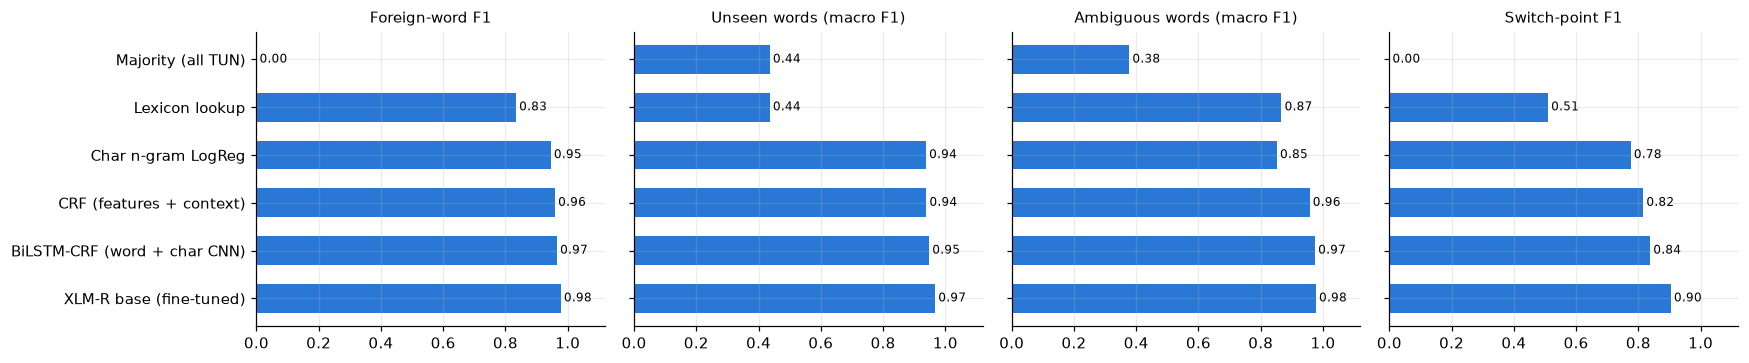

In [16]:
table = results_table(RESULTS)
save_results(table, TEST_PREDS, test)
num_cols = [c for c in table.columns if c != "FOR_F1_95CI"]
display(table.style.format({c: "{:.3f}" for c in num_cols})
        .highlight_max(subset=[c for c in num_cols if c != "dev_macro_F1"], color="#d6e6f9"))
plot_results(table); plt.show()

## 12. Error analysis

The best model (highest test FOR F1) against the lexicon: where do errors remain, and does context fix the ambiguous forms?

In [17]:
best_name = max([k for k in RESULTS if k != MajorityTagger.name], key=lambda k: RESULTS[k]["FOR_F1"])
print("best model:", best_name)
bp, lp = TEST_PREDS[best_name], TEST_PREDS[LexiconTagger.name]
rows = []
for s, p, lx in zip(test, bp, lp):
    for i, (t, w, g) in enumerate(zip(s["tokens"], s["norm"], s["labels"])):
        rows.append({"id": s["id"], "token": t, "norm": w, "gold": g, "pred": p[i], "lexicon": lx[i],
                     "type": "unseen" if w not in train_counts else ("ambiguous" if len(train_counts[w]) == 2 else "seen"),
                     "context": " ".join(s["tokens"][max(0, i-4):i] + [f"[{t}]"] + s["tokens"][i+1:i+5])})
err = pd.DataFrame(rows)
err.to_csv(TABLES / "error_analysis_best_model.csv", index=False)

display(pd.crosstab(err.gold, err.pred, rownames=["gold"], colnames=["predicted"]))
print("error rate by word type:")
display(err.assign(best_wrong=err.gold != err.pred, lexicon_wrong=err.gold != err.lexicon)
        .groupby("type")[["best_wrong", "lexicon_wrong"]].agg(["mean", "sum"]).round(3))
wrong = err[err.gold != err.pred]
print("most frequent wrong word forms:")
display(wrong.groupby(["norm", "gold", "pred"]).size().sort_values(ascending=False).head(10).to_frame("errors"))
print("sample errors in context:")
display(wrong.sample(min(15, len(wrong)), random_state=SEED)[["token", "gold", "pred", "type", "context"]])

best model: XLM-R base (fine-tuned)


predicted,FOR,TUN
gold,,
FOR,996,29
TUN,16,2337


error rate by word type:


best_wrong     lexicon_wrong     
                mean sum          mean  sum
type                                       
ambiguous      0.022   8         0.127   47
seen           0.007  13         0.007   13
unseen         0.023  24         0.226  240

most frequent wrong word forms:


,,,errors
norm,gold,pred,
ou,TUN,FOR,3
ba,FOR,TUN,1
admin,TUN,FOR,1
bavariyano,FOR,TUN,1
baz,FOR,TUN,1
bey,TUN,FOR,1
casqoutet,FOR,TUN,1
clubiste,TUN,FOR,1
dectoura,FOR,TUN,1


sample errors in context:


,token,gold,pred,type,context
3027,ou,TUN,FOR,ambiguous,ta3tim é3lemi fi télé [ou] la radio 9otlna mouchna
1765,ou,TUN,FOR,ambiguous,bidi n7areb tawa 7ans [ou] 3omri ans opk m3a
1802,flousse,TUN,FOR,unseen,ou ma ta7kich 3al [flousse] elli mechiya ki trab
3259,ettourisme,TUN,FOR,unseen,felli t7eb inti ma3ada [ettourisme]
2785,max,FOR,TUN,seen,mobilité max de chez [max] bil traitement et tt
3136,yaV,FOR,TUN,unseen,Oui [yaV] lgtmps paske kassrouh a
231,hdi,FOR,TUN,seen,s7i7 tenja7 c'est une [hdi] choufha ema diesel ma
804,koi,FOR,TUN,seen,ma ya9dhilek 7ad masalah [koi] kan ta9dhi na9dhilek makénéch
615,baz,FOR,TUN,seen,i4 maf3oulha mayoufech tosbor [baz] tal9a l'istintej Titrouet t9at9
199,MA,FOR,TUN,ambiguous,7ATA KI NA7KI A [MA] SOEUR AMA MEN GHIR


In [18]:
# Does context resolve the frequent ambiguous forms?
focus = ["la", "ma", "el", "en", "a", "le", "ki", "men", "ou", "si"]
summary = err[err.norm.isin(focus)].groupby("norm").apply(lambda d: pd.Series({
    "test tokens": len(d), "gold FOR %": 100 * (d.gold == "FOR").mean(),
    "lexicon acc %": 100 * (d.gold == d.lexicon).mean(), "best model acc %": 100 * (d.gold == d.pred).mean()}),
    include_groups=False)
display(summary.round(1).sort_values("test tokens", ascending=False))

,test tokens,gold FOR %,lexicon acc %,best model acc %
norm,,,,
el,53.0,0.0,100.0,100.0
le,26.0,80.8,80.8,96.2
ma,23.0,8.7,91.3,95.7
la,23.0,91.3,91.3,100.0
ou,21.0,19.0,81.0,85.7
a,15.0,100.0,100.0,100.0
ki,14.0,0.0,100.0,100.0
men,10.0,0.0,100.0,100.0
si,8.0,62.5,62.5,87.5


## 13. Robustness: cross-genre test (train on social / forum / blog, test on rap)

A random split mixes posts of the same sources in train and test. Here the fast models are retrained (same hyper-parameters) on
three genres and tested on **rap lyrics, a genre never seen in training**. These models are not saved.

In [19]:
src_g = [s for s in unique if s["genre"] != "rap"]
rap = [s for s in unique if s["genre"] == "rap"]
print(f"train: {len(src_g)} sentences (social/forum/blog) | test: {len(rap)} rap sentences, "
      f"{sum(len(s['tokens']) for s in rap)} words, {sum(s['labels'].count('FOR') for s in rap)} foreign")
counts_g = word_label_counts(src_g)
cross = {}
for m in (LexiconTagger(), CharNgramTagger(C=lr.C), CRFTagger(c1=crf.c1, c2=crf.c2)):
    m.fit(src_g)
    cross[m.name] = evaluate(rap, m.predict(rap), counts_g)
cross_df = pd.DataFrame(cross).T[["FOR_F1", "macro_F1", "unseen_macro_F1", "switch_point_F1"]]
cross_df["random-split FOR_F1"] = [RESULTS[k]["FOR_F1"] for k in cross_df.index]
cross_df.to_csv(TABLES / "cross_genre_rap.csv")
display(cross_df.round(3))

train: 2949 sentences (social/forum/blog) | test: 509 rap sentences, 8277 words, 1008 foreign


,FOR_F1,macro_F1,unseen_macro_F1,switch_point_F1,random-split FOR_F1
Lexicon lookup,0.462,0.703,0.461,0.347,0.834
Char n-gram LogReg,0.786,0.876,0.880,0.697,0.946
CRF (features + context),0.771,0.871,0.843,0.683,0.959


## 14. Live demo

These sentences were written for the demo (**not** from the corpus). Edit `DEMO` to try your own; foreign words appear in `[brackets]`.
The same thing is available from the command line: `python scripts/demo.py "your sentence"`.

In [20]:
DEMO = [
    "la la ma n7ebch nemchi la fac lyoum",
    "el film hedha vraiment 7lou barcha",
    "ena mech mte3 stress ama demain 3andi examen",
    "ya5i chbik ma t9olich ? c'est pas normal",
    "i love you barcha ya omi",
    "nchallah el weekend jey nemchiw lel plage",
]
demo = [make_sentence(tokenize_text(d)) for d in DEMO]
for i, s in enumerate(demo):
    print(f"\n{DEMO[i]}")
    for name, m in MODELS.items():
        if name != MajorityTagger.name:
            print(f"   {name:30} {tag_string(s['tokens'], m.predict([s])[0])}")


la la ma n7ebch nemchi la fac lyoum
   Lexicon lookup                 [la] [la] ma n7ebch nemchi [la] fac lyoum
   Char n-gram LogReg             [la] [la] ma n7ebch nemchi [la] [fac] lyoum
   CRF (features + context)       [la] [la] ma n7ebch nemchi [la] [fac] lyoum
   BiLSTM-CRF (word + char CNN)   la la ma n7ebch nemchi [la] [fac] lyoum
   XLM-R base (fine-tuned)        la la ma n7ebch nemchi la fac lyoum

el film hedha vraiment 7lou barcha
   Lexicon lookup                 el film hedha [vraiment] 7lou barcha
   Char n-gram LogReg             el [film] hedha [vraiment] 7lou barcha
   CRF (features + context)       el film hedha [vraiment] 7lou barcha
   BiLSTM-CRF (word + char CNN)   el film hedha [vraiment] 7lou barcha


   XLM-R base (fine-tuned)        el film hedha [vraiment] 7lou barcha

ena mech mte3 stress ama demain 3andi examen
   Lexicon lookup                 ena mech mte3 [stress] ama demain 3andi examen
   Char n-gram LogReg             ena mech mte3 [stress] ama [demain] 3andi [examen]
   CRF (features + context)       ena mech mte3 [stress] ama demain 3andi examen
   BiLSTM-CRF (word + char CNN)   ena mech mte3 stress ama demain 3andi [examen]
   XLM-R base (fine-tuned)        ena mech mte3 [stress] ama [demain] 3andi [examen]

ya5i chbik ma t9olich ? c'est pas normal
   Lexicon lookup                 ya5i chbik ma t9olich [c'est] [pas] [normal]
   Char n-gram LogReg             ya5i chbik ma t9olich [c'est] [pas] [normal]
   CRF (features + context)       ya5i chbik ma t9olich [c'est] [pas] [normal]
   BiLSTM-CRF (word + char CNN)   ya5i chbik ma t9olich [c'est] [pas] [normal]
   XLM-R base (fine-tuned)        ya5i chbik ma t9olich [c'est] [pas] [normal]

i love you barcha ya omi
   Lexi

## 15. Conclusion, limitations and references

**Findings** (from the tables above):

* Accuracy is a poor metric: "all Tunisian" already gets ≈ 70 %.
* Memorisation (lexicon) reaches ≈ 0.83 foreign-word F1 but fails on **unseen** spellings (≈ 31 % of test words).
* Character n-grams jump to ≈ 0.95 foreign F1 and fix most unseen words, but cannot use context, so ambiguous forms
  (`la`, `ma`, `le`, `en`) stay hard (≈ 0.85 ambiguous macro F1).
* Context models fix the ambiguous words: ≈ 0.96 (CRF) and ≈ 0.98 (BiLSTM-CRF, XLM-R) ambiguous macro F1.
  Fine-tuned **XLM-R is the best overall** on foreign-word, code-switched-sentence and switch-point F1.
* Remaining errors: short function words (`ou` = Tunisian *"and"* vs French *"or"*), English / brand words, and French-origin
  words written the Tunisian way (`flousse`, `ettourisme`, `clubiste`) where even the annotation is debatable.
* On an unseen genre (rap) the classical models drop from ≈ 0.95 to ≈ 0.78 foreign F1: random-split scores are optimistic.

**Limitations.** One random split and one training seed per model (the bootstrap interval reflects test sampling, not training
variance); "foreign" mixes French and English; MSA is inside the `arabizi` class; no author IDs, so one author's posts may appear in
both train and test.

**Extensions.** Separate French vs English; use the unlabelled TUNIZI corpus for further pre-training; transliterate Arabic-script
Tunisian corpora (e.g. TunSwitch transcripts) into Arabizi as extra training data.

**References.**
* E. Gugliotta, M. Dinarelli. *TArC: Tunisian Arabish Corpus, First complete release.* LREC 2022.
* E. Gugliotta, M. Dinarelli, O. Kraif. *Multi-Task Sequence Prediction for Tunisian Arabizi Multi-Level Annotation.* WANLP 2020.
* G. Lample et al. *Neural Architectures for Named Entity Recognition.* NAACL 2016.
* J. Lafferty, A. McCallum, F. Pereira. *Conditional Random Fields.* ICML 2001.
* A. Conneau et al. *Unsupervised Cross-lingual Representation Learning at Scale (XLM-R).* ACL 2020.